# Part C: Text Classification — SMS Spam Detection
**Model:** Logistic Regression | **Feature Extraction:** TF-IDF | **Dataset:** SMS Spam Collection

---
## 1. Importing Required Libraries
Importing all necessary libraries for data manipulation, text preprocessing, feature extraction, model training, hyperparameter tuning, evaluation, visualization, and model serialization.

In [1]:
import os
import re
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Download English stopwords dictionary
nltk.download('stopwords', quiet=True)

# Set visual style for plots
sns.set_theme(style="whitegrid")
print("All libraries imported successfully!")

All libraries imported successfully!


## 2. Loading & Inspecting the Raw Dataset
Loading the original `spam.csv` dataset without prior cleaning to examine:
- Dataset dimensions (number of rows and columns).
- Column names and data types (`info()`).
- Missing values across all columns (`isnull().sum()`).
- Duplicate records (`duplicated().sum()`).

In [2]:
# Load raw dataset
df_raw = pd.read_csv('spam.csv', encoding='latin-1')

print(f"Raw Dataset Shape: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns\n")
display(df_raw.head())

print("\n--- Dataset Structure & Data Types ---")
df_raw.info()

print("\n--- Missing Values Count ---")
print(df_raw.isnull().sum())

print(f"\n--- Duplicate Records ---")
print(f"Total duplicate rows: {df_raw.duplicated().sum()}")

Raw Dataset Shape: 5572 rows, 5 columns



,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
0,ham,"Go until jurong point, crazy.. Available only ...",NaN,NaN,NaN
1,ham,Ok lar... Joking wif u oni...,NaN,NaN,NaN
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,NaN,NaN,NaN
3,ham,U dun say so early hor... U c already then say...,NaN,NaN,NaN
4,ham,"Nah I don't think he goes to usf, he lives aro...",NaN,NaN,NaN



--- Dataset Structure & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   v1          5572 non-null   object
 1   v2          5572 non-null   object
 2   Unnamed: 2  50 non-null     object
 3   Unnamed: 3  12 non-null     object
 4   Unnamed: 4  6 non-null      object
dtypes: object(5)
memory usage: 217.8+ KB

--- Missing Values Count ---
v1               0
v2               0
Unnamed: 2    5522
Unnamed: 3    5560
Unnamed: 4    5566
dtype: int64

--- Duplicate Records ---
Total duplicate rows: 403


## 3. Tabular Data Cleaning & Target Encoding
Based on the initial raw inspection, the following cleaning steps are applied and justified:
1. **Drop Unnecessary Columns:** Columns `Unnamed: 2`, `Unnamed: 3`, and `Unnamed: 4` contain >99% missing values and carry no predictive value, so they are removed.
2. **Rename Columns:** Retaining `v1` and `v2` and renaming them to `label` and `text` for clarity.
3. **Remove Duplicates:** Dropping duplicate SMS messages to prevent identical messages from leaking across train, validation, and test splits.
4. **Target Encoding:** Mapping categorical labels into binary numeric targets (`ham` $\rightarrow$ `0`, `spam` $\rightarrow$ `1`).

In [3]:
# Keep relevant columns and rename
df = df_raw[['v1', 'v2']].copy()
df.columns = ['label', 'text']

# Remove duplicate rows
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

# Encode target labels
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

print(f"Cleaned Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Remaining Missing Values:\n{df.isnull().sum()}\n")
display(df.head())

Cleaned Dataset Shape: 5169 rows, 2 columns
Remaining Missing Values:
label    0
text     0
dtype: int64



,label,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


## 4. Exploratory Data Analysis (EDA)
Analyzing the cleaned dataset before text preprocessing to understand:
- **Class Balance:** Checking the exact counts and percentages of `Ham` (0) vs. `Spam` (1).
- **Text Length Characteristics:** Computing character count and word count per message to compare length patterns between legitimate and spam messages.

--- Class Distribution Summary ---


,Count,Percentage (%)
Ham (0),4516,87.37
Spam (1),653,12.63



--- Text Length Statistics by Class (0 = Ham, 1 = Spam) ---


word_count                                             char_count  \
           count   mean    std  min   25%   50%   75%    max      count   
label                                                                     
0         4516.0  14.13  11.12  1.0   7.0  11.0  18.0  171.0     4516.0   
1          653.0  23.68   5.97  2.0  22.0  25.0  28.0   35.0      653.0   

                                                        
         mean    std   min    25%    50%    75%    max  
label                                                   
0       70.46  56.36   2.0   34.0   52.0   90.0  910.0  
1      137.89  30.14  13.0  132.0  149.0  157.0  224.0

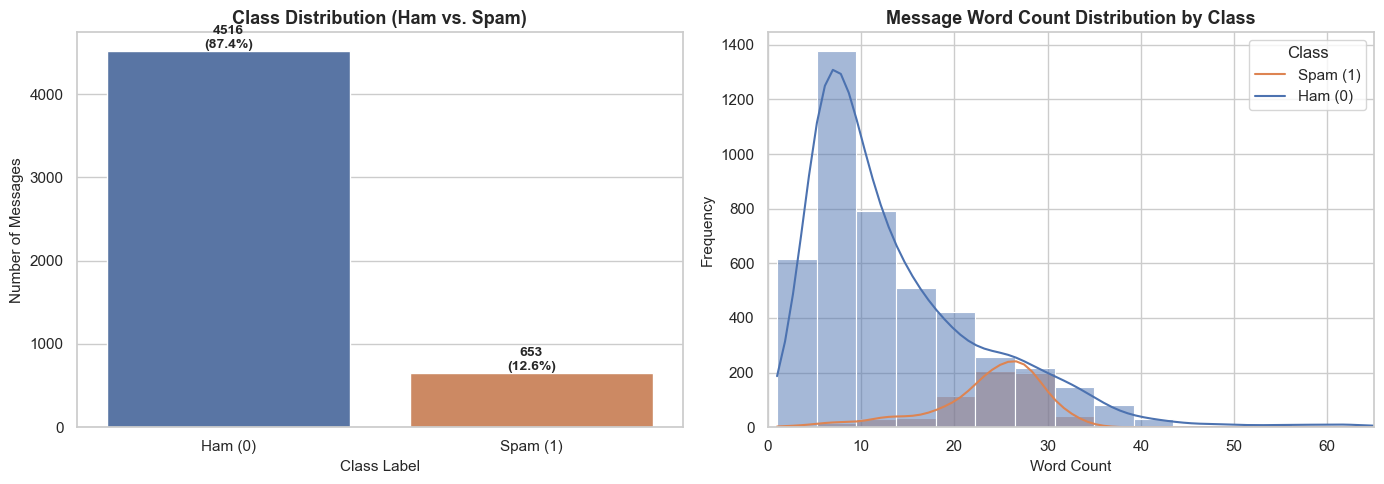

In [4]:
# Calculate text length features
df['char_count'] = df['text'].apply(len)
df['word_count'] = df['text'].apply(lambda x: len(x.split()))

# 1. Class distribution summary table
class_summary = pd.DataFrame({
    'Count': df['label'].value_counts(),
    'Percentage (%)': (df['label'].value_counts(normalize=True) * 100).round(2)
})
class_summary.index = ['Ham (0)', 'Spam (1)']
print("--- Class Distribution Summary ---")
display(class_summary)

# 2. Text length descriptive statistics by class
print("\n--- Text Length Statistics by Class (0 = Ham, 1 = Spam) ---")
display(df.groupby('label')[['word_count', 'char_count']].describe().round(2))

# 3. Visualizations
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot A: Class Imbalance Bar Chart
sns.countplot(data=df, x='label', hue='label', palette=['#4C72B0', '#DD8452'], legend=False, ax=axes[0])
axes[0].set_title('Class Distribution (Ham vs. Spam)', fontsize=13, fontweight='bold')
axes[0].set_xlabel('Class Label', fontsize=11)
axes[0].set_ylabel('Number of Messages', fontsize=11)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Ham (0)', 'Spam (1)'])

for p in axes[0].patches:
    pct = f'{100 * p.get_height() / len(df):.1f}%'
    axes[0].annotate(f'{int(p.get_height())}\n({pct})',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='bottom', fontsize=10, fontweight='bold')

# Plot B: Word Count Distribution
sns.histplot(data=df, x='word_count', hue='label', bins=40, kde=True,
             palette=['#4C72B0', '#DD8452'], ax=axes[1])
axes[1].set_title('Message Word Count Distribution by Class', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Word Count', fontsize=11)
axes[1].set_ylabel('Frequency', fontsize=11)
axes[1].set_xlim(0, 65)
axes[1].legend(title='Class', labels=['Spam (1)', 'Ham (0)'])

plt.tight_layout()
plt.show()

## 5. Text Cleaning & Preprocessing
Applying a standardized NLP preprocessing function to raw SMS text:
1. **Lowercasing:** Converting all characters to lowercase so words like `Free` and `free` are treated identically.
2. **HTML Tag Removal:** Stripping any embedded HTML tags (`<...>`).
3. **Punctuation & Number Removal:** Removing digits and special characters to retain only alphabetical tokens.
4. **Stopword Removal:** Filtering out high-frequency English stopwords (e.g., *the, is, in*) that carry minimal discriminative meaning.

In [5]:
stop_words = set(stopwords.words('english'))

def clean_text(text):
    # 1. Lowercase text
    text = text.lower()
    # 2. Remove HTML tags
    text = re.sub(r'<.*?>', '', text)
    # 3. Remove punctuation and numbers (keep letters and spaces only)
    text = re.sub(r'[^a-z\s]', '', text)
    # 4. Tokenize and remove stopwords
    tokens = [word for word in text.split() if word not in stop_words]
    return ' '.join(tokens)

# Apply preprocessing
df['clean_text'] = df['text'].apply(clean_text)

# Display before vs. after comparison
print("--- Text Preprocessing Comparison (Before vs. After) ---")
display(df[['label', 'text', 'clean_text']].head(8))

--- Text Preprocessing Comparison (Before vs. After) ---


,label,text,clean_text
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah dont think goes usf lives around though
5,1,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey darling weeks word back id like fu...
6,0,Even my brother is not like to speak with me. ...,even brother like speak treat like aids patent
7,0,As per your request 'Melle Melle (Oru Minnamin...,per request melle melle oru minnaminunginte nu...


## 6. Train / Validation / Test Splitting
Splitting the preprocessed dataset into **70% Training, 15% Validation, and 15% Test** sets:
- **Stratification (`stratify=y`):** Ensures the ~87.4% Ham / ~12.6% Spam class proportion is strictly preserved across all three splits.
- **Reproducibility (`random_state=42`):** Guarantees identical data splits across runs.

In [6]:
X = df['clean_text']
y = df['label']

# First split: 70% Train, 30% Temp (Validation + Test)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=42
)

# Second split: 15% Validation, 15% Test (50% of the 30% Temp)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

# Summary table of splits
split_summary = pd.DataFrame({
    'Samples': [len(X_train), len(X_val), len(X_test)],
    'Percentage (%)': [
        round(len(X_train)/len(df)*100, 1),
        round(len(X_val)/len(df)*100, 1),
        round(len(X_test)/len(df)*100, 1)
    ],
    'Spam Ratio (%)': [
        round(y_train.mean()*100, 2),
        round(y_val.mean()*100, 2),
        round(y_test.mean()*100, 2)
    ]
}, index=['Training Set', 'Validation Set', 'Test Set'])

display(split_summary)

,Samples,Percentage (%),Spam Ratio (%)
Training Set,3618,70.0,12.63
Validation Set,775,15.0,12.65
Test Set,776,15.0,12.63


## 7. Feature Extraction using TF-IDF
Transforming cleaned text into numerical feature vectors using **TF-IDF (Term Frequency–Inverse Document Frequency)**:
- **Why TF-IDF?** Unlike simple word counts, TF-IDF penalizes words that appear across many messages and boosts words that are distinctive to spam messages.
- **Data Leakage Prevention:** `TfidfVectorizer` is fitted **strictly on the training data (`X_train`)**, and then used to transform `X_val` and `X_test`.
- **Vocabulary Size:** Capped at `max_features=3000` most informative terms to prevent overfitting and keep dimensionality compact.

In [7]:
tfidf = TfidfVectorizer(max_features=3000)

# Fit ONLY on training data, then transform all sets
X_train_tfidf = tfidf.fit_transform(X_train)
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print(f"Final Vocabulary Size: {len(tfidf.vocabulary_)} unique tokens")
print(f"Training Feature Matrix Shape:   {X_train_tfidf.shape}")
print(f"Validation Feature Matrix Shape: {X_val_tfidf.shape}")
print(f"Test Feature Matrix Shape:       {X_test_tfidf.shape}")

Final Vocabulary Size: 3000 unique tokens
Training Feature Matrix Shape:   (3618, 3000)
Validation Feature Matrix Shape: (775, 3000)
Test Feature Matrix Shape:       (776, 3000)


## 8. Model Training & Hyperparameter Tuning (Validation Set Only)
Training a **Logistic Regression** classifier and tuning its inverse regularization strength parameter **`C`** across `[0.01, 0.1, 1, 5, 10, 20]`:
- Smaller `C` applies stronger regularization (prevents overfitting); larger `C` allows the model to fit training features more closely.
- Because the dataset is imbalanced (~12.6% Spam), **Validation F1-Score for the Spam class** is used alongside Accuracy to select the optimal `C`.

,C,Val Accuracy,Val Precision (Spam),Val Recall (Spam),Val F1-Score (Spam)
0,0.01,0.8735,0.0000,0.0000,0.0000
1,0.10,0.8735,0.0000,0.0000,0.0000
2,1.00,0.9471,0.9831,0.5918,0.7389
3,5.00,0.9613,0.9595,0.7245,0.8256
4,10.00,0.9652,0.9610,0.7551,0.8457
5,20.00,0.9639,0.9487,0.7551,0.8409



Optimal Hyperparameter Selected (Validation Set): C = 10.0


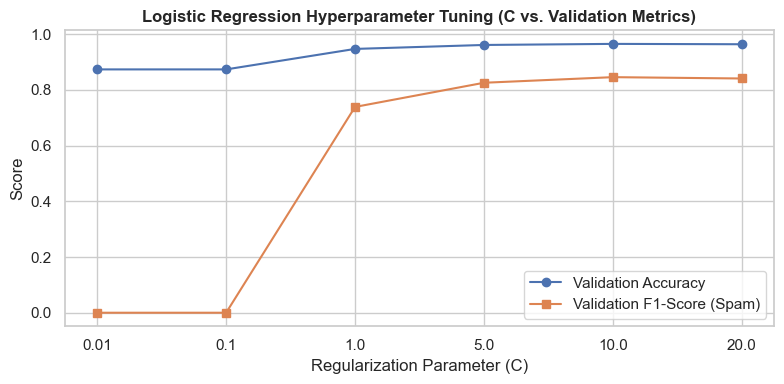

In [8]:
c_candidates = [0.01, 0.1, 1, 5, 10, 20]
tuning_records = []

for c in c_candidates:
    model = LogisticRegression(C=c, max_iter=1000, random_state=42)
    model.fit(X_train_tfidf, y_train)
    
    val_preds = model.predict(X_val_tfidf)
    tuning_records.append({
        'C': c,
        'Val Accuracy': accuracy_score(y_val, val_preds),
        'Val Precision (Spam)': precision_score(y_val, val_preds, zero_division=0),
        'Val Recall (Spam)': recall_score(y_val, val_preds),
        'Val F1-Score (Spam)': f1_score(y_val, val_preds)
    })

tuning_df = pd.DataFrame(tuning_records)
display(tuning_df.round(4))

# Select best C based on highest Validation F1-Score for Spam
best_c = tuning_df.loc[tuning_df['Val F1-Score (Spam)'].idxmax(), 'C']
print(f"\nOptimal Hyperparameter Selected (Validation Set): C = {best_c}")

# Plot tuning curve
plt.figure(figsize=(8, 4))
plt.plot(tuning_df['C'].astype(str), tuning_df['Val Accuracy'], marker='o', label='Validation Accuracy')
plt.plot(tuning_df['C'].astype(str), tuning_df['Val F1-Score (Spam)'], marker='s', label='Validation F1-Score (Spam)')
plt.title('Logistic Regression Hyperparameter Tuning (C vs. Validation Metrics)', fontweight='bold')
plt.xlabel('Regularization Parameter (C)')
plt.ylabel('Score')
plt.legend()
plt.tight_layout()
plt.show()

## 9. Final Model Evaluation on the Unseen Test Set
Training the final Logistic Regression model with the optimal `C` selected from validation, and evaluating it **once** on the held-out test set using:
- Overall Test Accuracy.
- Per-class Precision, Recall, and F1-Score.
- Confusion Matrix (counts and percentages).

Final Test Accuracy (Logistic Regression, C=10.0): 0.9768 (97.68%)

--- Per-Class Classification Report ---
              precision    recall  f1-score   support

     Ham (0)     0.9741    1.0000    0.9869       678
    Spam (1)     1.0000    0.8163    0.8989        98

    accuracy                         0.9768       776
   macro avg     0.9871    0.9082    0.9429       776
weighted avg     0.9774    0.9768    0.9758       776



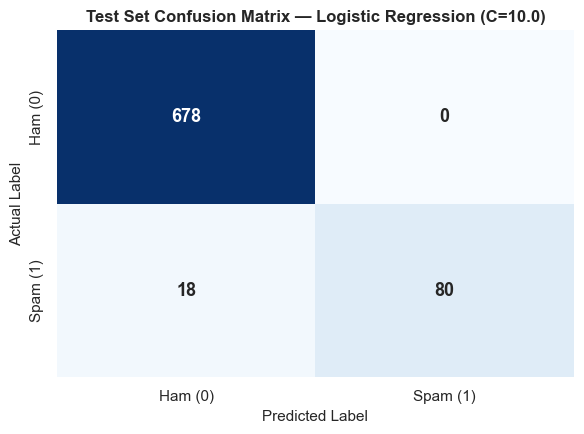

In [9]:
# Train final model with optimal C
final_lr = LogisticRegression(C=best_c, max_iter=1000, random_state=42)
final_lr.fit(X_train_tfidf, y_train)

# Predict ONCE on the unseen test set
test_preds = final_lr.predict(X_test_tfidf)

test_acc = accuracy_score(y_test, test_preds)
print(f"============================================================")
print(f"Final Test Accuracy (Logistic Regression, C={best_c}): {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"============================================================\n")

print("--- Per-Class Classification Report ---")
print(classification_report(y_test, test_preds, target_names=['Ham (0)', 'Spam (1)'], digits=4))

# Plot Confusion Matrix
cm = confusion_matrix(y_test, test_preds)
plt.figure(figsize=(6, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Ham (0)', 'Spam (1)'],
            yticklabels=['Ham (0)', 'Spam (1)'],
            annot_kws={'size': 13, 'weight': 'bold'})
plt.title(f'Test Set Confusion Matrix — Logistic Regression (C={best_c})', fontsize=12, fontweight='bold')
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('Actual Label', fontsize=11)
plt.tight_layout()
plt.show()

## 10. Saving Trained Model & Vectorizer for GUI Deployment
Serializing the fitted `TfidfVectorizer` and the trained `LogisticRegression` model to disk using `joblib` so the GUI can load them directly for real-time inference without retraining.

In [10]:
os.makedirs('models', exist_ok=True)

model_path = 'models/logistic_regression_spam.pkl'
vectorizer_path = 'models/tfidf_vectorizer.pkl'

joblib.dump(final_lr, model_path)
joblib.dump(tfidf, vectorizer_path)

print(f"Model saved successfully to:      {model_path}")
print(f"Vectorizer saved successfully to: {vectorizer_path}")

# Quick sanity check: reload and test on two sample messages
loaded_vec = joblib.load(vectorizer_path)
loaded_model = joblib.load(model_path)

sample_msgs = [
    "Congratulations! You won a FREE $1000 gift card. Claim now!",
    "Hey, are we still meeting at the library at 5 pm today?"
]
cleaned_samples = [clean_text(m) for m in sample_msgs]
sample_preds = loaded_model.predict(loaded_vec.transform(cleaned_samples))

print("\n--- Sanity Check on New Unseen Messages ---")
for msg, pred in zip(sample_msgs, sample_preds):
    label_str = "SPAM (1)" if pred == 1 else "HAM (0)"
    print(f"Message: '{msg}'  -->  Prediction: {label_str}")

Model saved successfully to:      models/logistic_regression_spam.pkl
Vectorizer saved successfully to: models/tfidf_vectorizer.pkl

--- Sanity Check on New Unseen Messages ---
Message: 'Congratulations! You won a FREE $1000 gift card. Claim now!'  -->  Prediction: SPAM (1)
Message: 'Hey, are we still meeting at the library at 5 pm today?'  -->  Prediction: HAM (0)
